# App Insights Analysis — Python Workbook

**Project goal:** Analyze Google Play Store apps and user reviews to understand ratings, installs, categories, app size, pricing, update patterns, and review sentiment.

1. Open this notebook in Jupyter Notebook
2. Keep `googleplaystore(2).csv` and `googleplaystore_user_reviews(2).csv` in the same folder as this notebook, upload both CSV files using the Files panel.
3. Run each cell from top to bottom using **Shift + Enter**.
4. Read the explanation under each section and save your charts/results for your report.

## 1. Import libraries

In [115]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_theme()

## 2. Load the two datasets

In [116]:
apps = pd.read_csv("C://Users//ankus//Downloads//JobAaj Project//EDA Project//EDA01 Project//googleplaystore(2).csv")
reviews = pd.read_csv("C://Users//ankus//Downloads//JobAaj Project//EDA Project//EDA01 Project//googleplaystore_user_reviews(2).csv")

print("Apps dataset shape:", apps.shape)
print("Reviews dataset shape:", reviews.shape)

display(apps.head())
display(reviews.head())

Apps dataset shape: (10841, 13)
Reviews dataset shape: (64295, 5)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


## 3. Inspect the data before cleaning

In [117]:
apps.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [118]:
display(apps.isna().sum().sort_values(ascending=False).to_frame("Missing values"))
display(apps.describe(include="all").T)

,Missing values
Rating,1474
Current Ver,8
Android Ver,3
Content Rating,1
Type,1
Size,0
Reviews,0
Category,0
App,0
Price,0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
App,10841,9660,ROBLOX,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,10841,34,FAMILY,1972,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9367.0,NaN,NaN,NaN,4.193338,0.537431,1.0,4.0,4.3,4.5,19.0
Reviews,10841,6002,0,596,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Size,10841,462,Varies with device,1695,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Installs,10841,22,"1,000,000+",1579,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10840,3,Free,10039,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,10841,93,0,10040,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Content Rating,10840,6,Everyone,8714,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Genres,10841,120,Tools,842,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [119]:
reviews.info()
display(reviews.isna().sum().sort_values(ascending=False).to_frame("Missing values"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  object 
 1   Translated_Review       37427 non-null  object 
 2   Sentiment               37432 non-null  object 
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), object(3)
memory usage: 2.5+ MB


,Missing values
Translated_Review,26868
Sentiment_Polarity,26863
Sentiment,26863
Sentiment_Subjectivity,26863
App,0


## 4. Clean and prepare the apps data

In [120]:
apps_clean = apps.copy()

# Remove the malformed row if present
apps_clean = apps_clean[apps_clean["Category"].astype(str).str.strip() != "1.9"].copy()

# Remove exact duplicate rows
before = len(apps_clean)
apps_clean = apps_clean.drop_duplicates().copy()
print("Exact duplicate rows removed:", before - len(apps_clean))

# Standardize whitespace in text columns
for col in ["App", "Category", "Type", "Content Rating", "Genres"]:
    apps_clean[col] = apps_clean[col].astype("string").str.strip()

# Numeric conversions
apps_clean["Rating"] = pd.to_numeric(apps_clean["Rating"], errors="coerce")
apps_clean["Reviews_num"] = pd.to_numeric(apps_clean["Reviews"], errors="coerce")

apps_clean["Installs_num"] = pd.to_numeric(
    apps_clean["Installs"].astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False),
    errors="coerce"
)

apps_clean["Price_num"] = pd.to_numeric(
    apps_clean["Price"].astype(str).str.replace("$", "", regex=False),
    errors="coerce"
)

def size_to_mb(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value == "Varies with device":
        return np.nan
    try:
        if value.endswith("M"):
            return float(value[:-1])
        if value.endswith("k"):
            return float(value[:-1]) / 1024
        return float(value)
    except ValueError:
        return np.nan

apps_clean["Size_MB"] = apps_clean["Size"].apply(size_to_mb)
apps_clean["Last Updated_dt"] = pd.to_datetime(
    apps_clean["Last Updated"], errors="coerce"
)

print("Rows before cleaning:", len(apps))
print("Rows after cleaning:", len(apps_clean))
display(apps_clean.head())

Exact duplicate rows removed: 483
Rows before cleaning: 10841
Rows after cleaning: 10357


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver,Reviews_num,Installs_num,Price_num,Size_MB,Last Updated_dt
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up,159,10000,0.0,19.0,2018-01-07
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up,967,500000,0.0,14.0,2018-01-15
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up,87510,5000000,0.0,8.7,2018-08-01
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up,215644,50000000,0.0,25.0,2018-06-08
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up,967,100000,0.0,2.8,2018-06-20


### Check the cleaned columns

In [121]:
display(apps_clean[[
    "App", "Category", "Rating", "Reviews_num",
    "Size", "Size_MB", "Installs", "Installs_num",
    "Type", "Price_num", "Last Updated_dt"
]].head(10))

,App,Category,Rating,Reviews_num,Size,Size_MB,Installs,Installs_num,Type,Price_num,Last Updated_dt
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,19.0,"10,000+",10000,Free,0.0,2018-01-07
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,14.0,"500,000+",500000,Free,0.0,2018-01-15
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,8.7,"5,000,000+",5000000,Free,0.0,2018-08-01
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,25.0,"50,000,000+",50000000,Free,0.0,2018-06-08
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,2.8,"100,000+",100000,Free,0.0,2018-06-20
5,Paper flowers instructions,ART_AND_DESIGN,4.4,167,5.6M,5.6,"50,000+",50000,Free,0.0,2017-03-26
6,Smoke Effect Photo Maker - Smoke Editor,ART_AND_DESIGN,3.8,178,19M,19.0,"50,000+",50000,Free,0.0,2018-04-26
7,Infinite Painter,ART_AND_DESIGN,4.1,36815,29M,29.0,"1,000,000+",1000000,Free,0.0,2018-06-14
8,Garden Coloring Book,ART_AND_DESIGN,4.4,13791,33M,33.0,"1,000,000+",1000000,Free,0.0,2017-09-20
9,Kids Paint Free - Drawing Fun,ART_AND_DESIGN,4.7,121,3.1M,3.1,"10,000+",10000,Free,0.0,2018-07-03


## 5. Basic-level questions

### Basic Q1 — What is the average rating?

In [122]:
average_rating = apps_clean["Rating"].mean()
print(f"Average app rating: {average_rating:.2f} / 5")

Average app rating: 4.19 / 5


### Basic Q2 — How many unique app categories are there?

In [123]:
category_count = apps_clean["Category"].nunique()
print("Number of unique categories:", category_count)

Number of unique categories: 33


### Basic Q3 — What is the distribution of app sizes?

count    8831.000000
mean       21.287413
std        22.540591
min         0.008301
25%         4.700000
50%        13.000000
75%        29.000000
max       100.000000
Name: Size_MB, dtype: float64


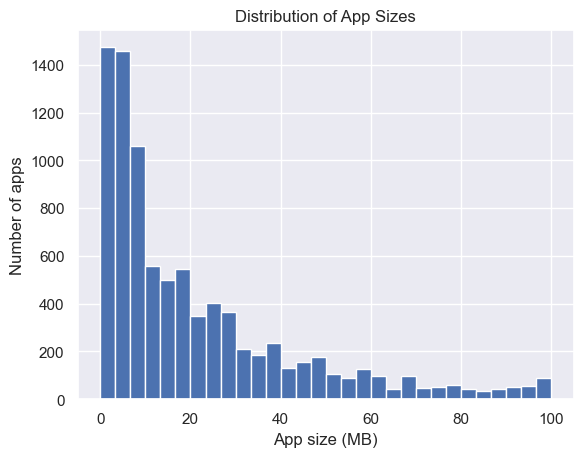

In [124]:
print(apps_clean["Size_MB"].describe())
apps_clean["Size_MB"].dropna().plot(kind="hist", bins=30)
plt.title("Distribution of App Sizes")
plt.xlabel("App size (MB)")
plt.ylabel("Number of apps")
plt.show()

### Basic Q4 — How many free vs paid apps are there?

In [125]:
display(apps_clean["Type"].value_counts(dropna=False).to_frame("App count"))

,App count
Type,
Free,9591
Paid,765
<NA>,1


### Basic Q5 — What is the most common content rating?

In [126]:
display(apps_clean["Content Rating"].mode())
display(apps_clean["Content Rating"].value_counts().head(10))

0    Everyone
Name: Content Rating, dtype: string

Content Rating
Everyone           8382
Teen               1146
Mature 17+          447
Everyone 10+        377
Adults only 18+       3
Unrated               2
Name: count, dtype: Int64

### Basic Q6 — What are the top 5 most installed apps?

In [127]:
top_installed = apps_clean.sort_values("Installs_num", ascending=False)[
    ["App", "Category", "Installs", "Installs_num", "Rating"]
].head(5)
display(top_installed)

,App,Category,Installs,Installs_num,Rating
3454,Google Drive,PRODUCTIVITY,"1,000,000,000+",1000000000,4.4
865,Google Play Games,ENTERTAINMENT,"1,000,000,000+",1000000000,4.3
3523,Google Drive,PRODUCTIVITY,"1,000,000,000+",1000000000,4.4
2544,Facebook,SOCIAL,"1,000,000,000+",1000000000,4.1
2545,Instagram,SOCIAL,"1,000,000,000+",1000000000,4.5


### Basic Q7 — How many apps have a rating of 4.0 and above?

In [128]:
count_rating_4 = (apps_clean["Rating"] >= 4.0).sum()
print("Apps rated 4.0 or above:", count_rating_4)

Apps rated 4.0 or above: 6947


### Basic Q8 — What is the average number of reviews for free vs paid apps?

In [129]:
display(
    apps_clean.groupby("Type", dropna=False)["Reviews_num"]
    .mean().sort_values(ascending=False).to_frame("Average reviews")
)

,Average reviews
Type,
Free,437373.593056
Paid,11900.550327
<NA>,0.000000


### Basic Q9 — What is the average app size for each category?

,Average size (MB)
Category,
GAME,44.126816
FAMILY,27.930205
TRAVEL_AND_LOCAL,24.515960
SPORTS,24.180992
ENTERTAINMENT,22.638806
PARENTING,22.512963
FOOD_AND_DRINK,22.056122
HEALTH_AND_FITNESS,21.642819
EDUCATION,20.076632


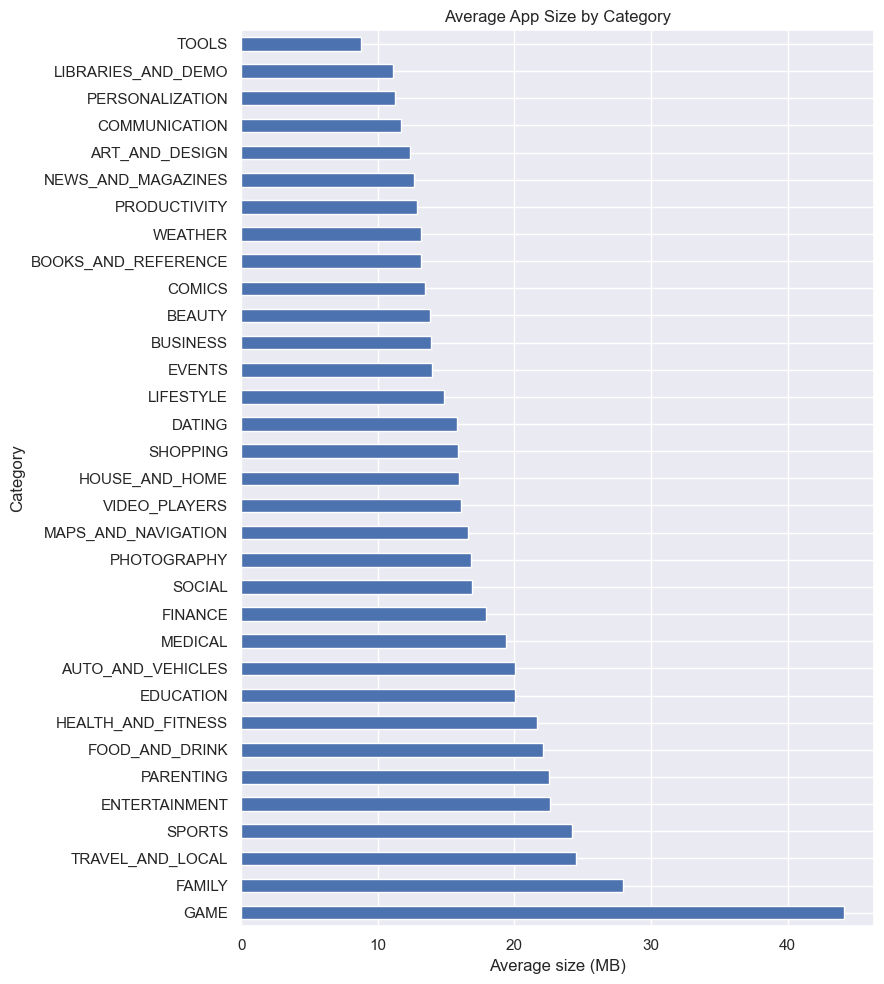

In [130]:
avg_size_category = (
    apps_clean.groupby("Category")["Size_MB"]
    .mean().sort_values(ascending=False)
)
display(avg_size_category.to_frame("Average size (MB)"))
avg_size_category.plot(kind="barh", figsize=(9, 10))
plt.title("Average App Size by Category")
plt.xlabel("Average size (MB)")
plt.tight_layout()
plt.show()

### Basic Q10 — How many apps were last updated in 2018?

In [131]:
updated_2018 = (apps_clean["Last Updated_dt"].dt.year == 2018).sum()
print("Apps last updated in 2018:", updated_2018)

Apps last updated in 2018: 6934


## 6. Medium-level questions

### Medium Q1 — What is the correlation between installs and rating?

In [132]:
corr_installs_rating = apps_clean[["Installs_num", "Rating"]].corr().loc["Installs_num", "Rating"]
print(f"Correlation between installs and rating: {corr_installs_rating:.3f}")

Correlation between installs and rating: 0.051


### Medium Q2 — Which categories have the highest average rating?

In [133]:
category_ratings = (
    apps_clean.groupby("Category")
    .agg(average_rating=("Rating", "mean"), app_count=("App", "count"))
    .sort_values("average_rating", ascending=False)
)
display(category_ratings.head(10))

,average_rating,app_count
Category,,
EVENTS,4.435556,64
EDUCATION,4.375969,130
ART_AND_DESIGN,4.358065,65
BOOKS_AND_REFERENCE,4.347458,230
PERSONALIZATION,4.333871,388
PARENTING,4.300000,60
GAME,4.281285,1121
BEAUTY,4.278571,53
HEALTH_AND_FITNESS,4.261450,306


### Medium Q3 — How does app price affect average rating? (Paid apps only)

,mean,count
Price_num,,
0.99,4.298095,105
1.00,4.450000,2
1.04,NaN,0
1.20,4.200000,1
1.26,NaN,0
1.29,4.100000,1
1.49,4.196774,31
1.50,4.200000,1
1.59,4.500000,1


Price-rating correlation among paid apps: -0.113


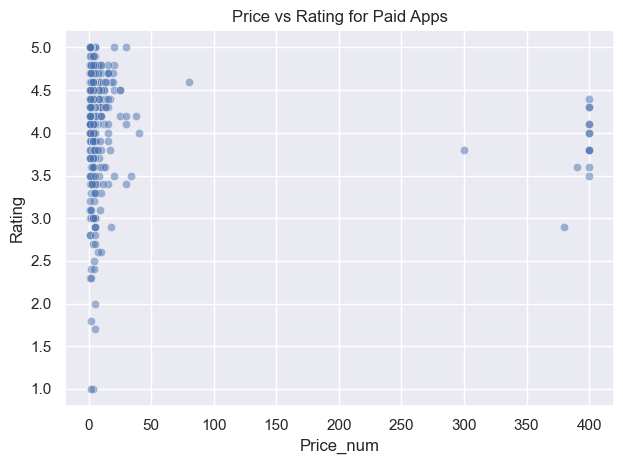

In [134]:
paid = apps_clean[apps_clean["Price_num"] > 0].copy()
display(paid.groupby("Price_num")["Rating"].agg(["mean", "count"]).sort_index())

price_rating_corr = paid[["Price_num", "Rating"]].corr().loc["Price_num", "Rating"]
print(f"Price-rating correlation among paid apps: {price_rating_corr:.3f}")

sns.scatterplot(data=paid, x="Price_num", y="Rating", alpha=0.5)
plt.title("Price vs Rating for Paid Apps")
plt.tight_layout()
plt.show()

### Medium Q4 — What is the rating distribution across content ratings?

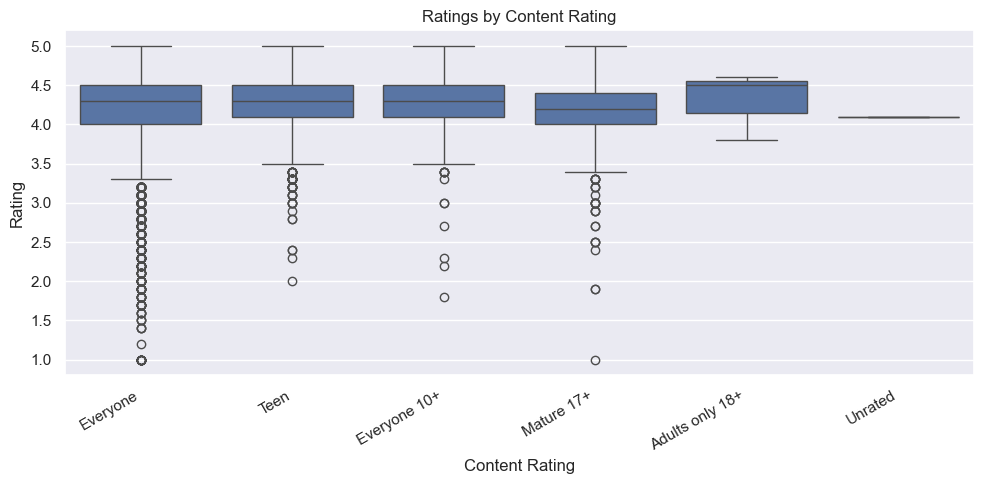

,mean,median,count
Content Rating,,,
Adults only 18+,4.300000,4.5,3
Everyone,4.180817,4.3,7095
Everyone 10+,4.254167,4.3,360
Mature 17+,4.124331,4.2,411
Teen,4.238845,4.3,1022
Unrated,4.100000,4.1,1


In [135]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=apps_clean, x="Content Rating", y="Rating")
plt.xticks(rotation=30, ha="right")
plt.title("Ratings by Content Rating")
plt.tight_layout()
plt.show()

display(apps_clean.groupby("Content Rating")["Rating"].agg(["mean", "median", "count"]))

### Medium Q5 — Which genres have the most apps with over 1 million installs?

In [136]:
over_1m = apps_clean[apps_clean["Installs_num"] > 1_000_000]
display(over_1m["Genres"].value_counts().head(10).to_frame("Apps over 1M installs"))

,Apps over 1M installs
Genres,
Tools,187
Action,182
Photography,161
Communication,146
Productivity,124
Arcade,113
Sports,109
Social,107
Entertainment,103


### Medium Q6 — How frequently do apps get updated?

In [137]:
display(apps_clean["Last Updated_dt"].dt.year.value_counts().sort_index().to_frame("Apps by last-update year"))

,Apps by last-update year
Last Updated_dt,
2010,1
2011,15
2012,26
2013,108
2014,204
2015,454
2016,789
2017,1826
2018,6934


### Medium Q7 — What is the impact of app size on installs?

Correlation between size and installs: 0.169


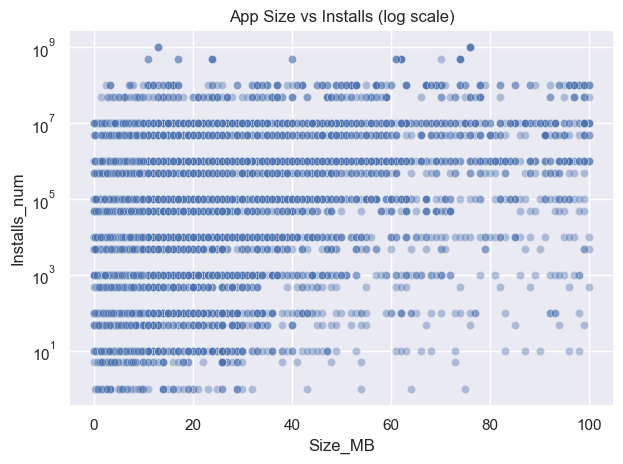

In [138]:
size_installs_corr = apps_clean[["Size_MB", "Installs_num"]].corr().loc["Size_MB", "Installs_num"]
print(f"Correlation between size and installs: {size_installs_corr:.3f}")

sns.scatterplot(data=apps_clean, x="Size_MB", y="Installs_num", alpha=0.4)
plt.yscale("log")
plt.title("App Size vs Installs (log scale)")
plt.tight_layout()
plt.show()

### Medium Q8 — Which apps have the highest number of reviews, and what are their ratings?

In [139]:
top_reviews = apps_clean.sort_values("Reviews_num", ascending=False)[
    ["App", "Reviews_num", "Rating", "Installs", "Category"]
].head(10)
display(top_reviews)

,App,Reviews_num,Rating,Installs,Category
2544,Facebook,78158306,4.1,"1,000,000,000+",SOCIAL
3943,Facebook,78128208,4.1,"1,000,000,000+",SOCIAL
336,WhatsApp Messenger,69119316,4.4,"1,000,000,000+",COMMUNICATION
3904,WhatsApp Messenger,69109672,4.4,"1,000,000,000+",COMMUNICATION
2604,Instagram,66577446,4.5,"1,000,000,000+",SOCIAL
2545,Instagram,66577313,4.5,"1,000,000,000+",SOCIAL
3909,Instagram,66509917,4.5,"1,000,000,000+",SOCIAL
382,Messenger – Text and Video Chat for Free,56646578,4.0,"1,000,000,000+",COMMUNICATION
335,Messenger – Text and Video Chat for Free,56642847,4.0,"1,000,000,000+",COMMUNICATION
1879,Clash of Clans,44893888,4.6,"100,000,000+",GAME


### Medium Q9 — How does content rating distribution differ between free and paid apps?

Type,Free,Paid
Content Rating,,
Adults only 18+,3,0
Everyone,7720,662
Everyone 10+,344,32
Mature 17+,428,19
Teen,1094,52
Unrated,2,0


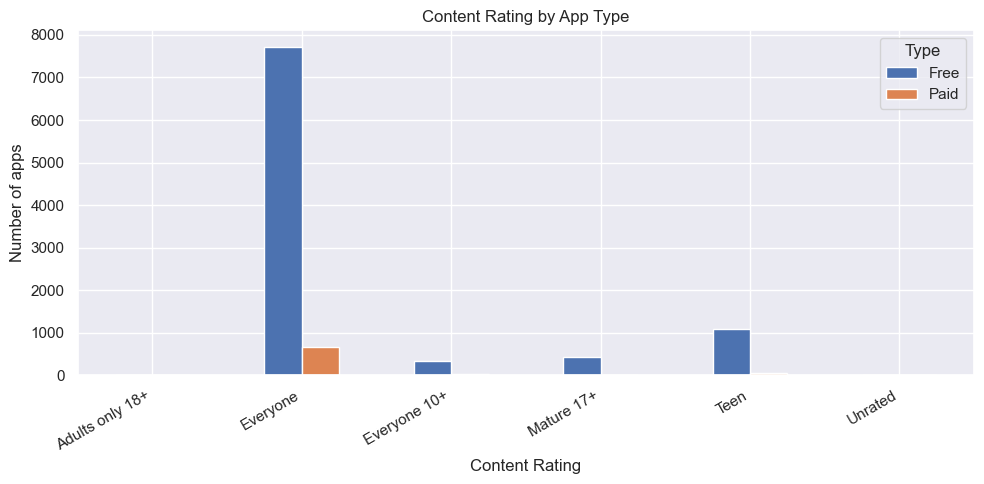

In [140]:
content_type_table = pd.crosstab(apps_clean["Content Rating"], apps_clean["Type"])
display(content_type_table)
content_type_table.plot(kind="bar", figsize=(10, 5))
plt.title("Content Rating by App Type")
plt.ylabel("Number of apps")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### Medium Q10 — What are the top 5 categories with the most installs?

,Total listed installs
Category,
GAME,31544024415
COMMUNICATION,24152276251
SOCIAL,12513867902
PRODUCTIVITY,12463091369
TOOLS,11452771915


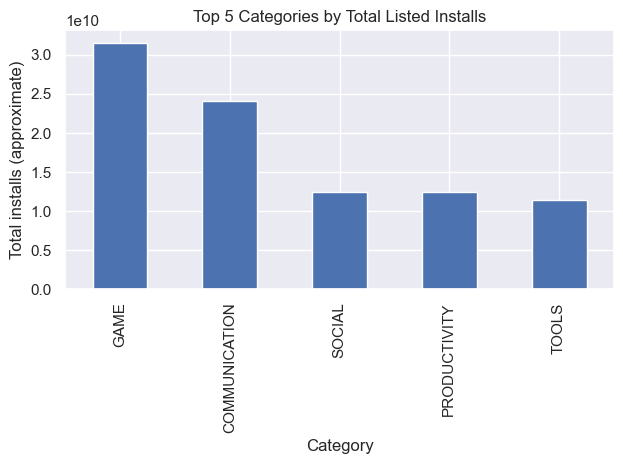

In [141]:
top_categories_installs = (
    apps_clean.groupby("Category")["Installs_num"]
    .sum().sort_values(ascending=False).head(5)
)
display(top_categories_installs.to_frame("Total listed installs"))
top_categories_installs.plot(kind="bar")
plt.title("Top 5 Categories by Total Listed Installs")
plt.ylabel("Total installs (approximate)")
plt.tight_layout()
plt.show()

## 7. Advanced-level questions

### Advanced Q1 — Top 10 highest-rated apps; compare reviews and installs

In [142]:
top_rated = (
    apps_clean[apps_clean["Reviews_num"] >= 100]
    .sort_values(["Rating", "Reviews_num"], ascending=[False, False])
    [["App", "Rating", "Reviews_num", "Installs", "Category"]]
    .head(10)
)
display(top_rated)

,App,Rating,Reviews_num,Installs,Category
10357,Ríos de Fe,5.0,141,"1,000+",LIFESTYLE
10301,"FD Calculator (EMI, SIP, RD & Loan Eligilibility)",5.0,104,"1,000+",FINANCE
8058,Oración CX,5.0,103,"5,000+",LIFESTYLE
6823,Barisal University App-BU Face,5.0,100,"1,000+",FAMILY
9625,JW Library,4.9,922752,"10,000,000+",BOOKS_AND_REFERENCE
1260,Six Pack in 30 Days - Abs Workout,4.9,272337,"10,000,000+",HEALTH_AND_FITNESS
4854,Six Pack in 30 Days - Abs Workout,4.9,272172,"10,000,000+",HEALTH_AND_FITNESS
79,Tickets + PDA 2018 Exam,4.9,197136,"1,000,000+",AUTO_AND_VEHICLES
712,"Learn Japanese, Korean, Chinese Offline & Free",4.9,133136,"1,000,000+",EDUCATION
2344,Period Tracker,4.9,100082,"1,000,000+",MEDICAL


### Advanced Q2 — Analyze update trends over time

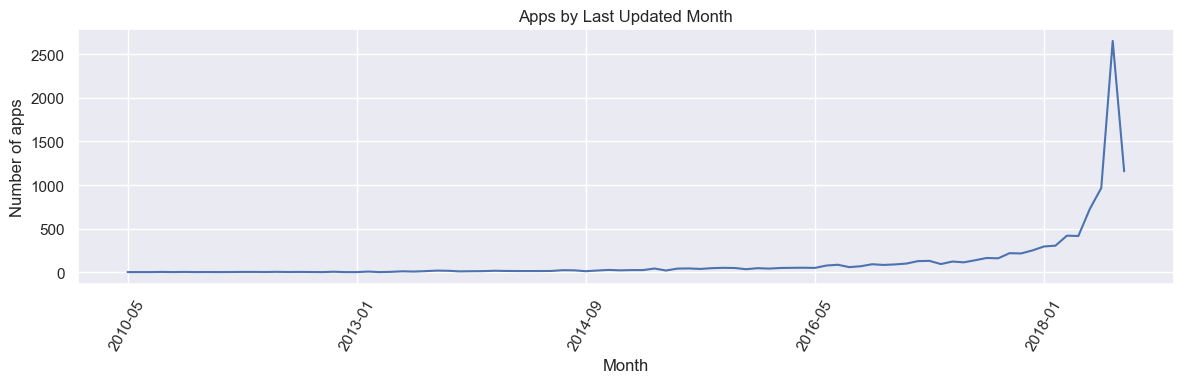

,Last-update count
Last Updated_dt,
2010,1
2011,15
2012,26
2013,108
2014,204
2015,454
2016,789
2017,1826
2018,6934


In [143]:
updates_by_month = (
    apps_clean.dropna(subset=["Last Updated_dt"])
    .assign(UpdateMonth=lambda d: d["Last Updated_dt"].dt.to_period("M").astype(str))
    ["UpdateMonth"].value_counts().sort_index()
)
updates_by_month.plot(figsize=(12, 4))
plt.title("Apps by Last Updated Month")
plt.xlabel("Month")
plt.ylabel("Number of apps")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

display(apps_clean["Last Updated_dt"].dt.year.value_counts().sort_index().to_frame("Last-update count"))

### Advanced Q3 — How does average rating change with installs? Create bins

,mean,median,count
Install_band,,,
<=1K,4.198504,4.4,1337
1K-10K,4.031095,4.2,1415
10K-100K,4.094593,4.2,1572
100K-1M,4.207043,4.3,2002
1M-10M,4.285675,4.3,1815
10M-100M,4.382995,4.4,641
100M-1B,4.309091,4.3,110
>1B,NaN,NaN,0


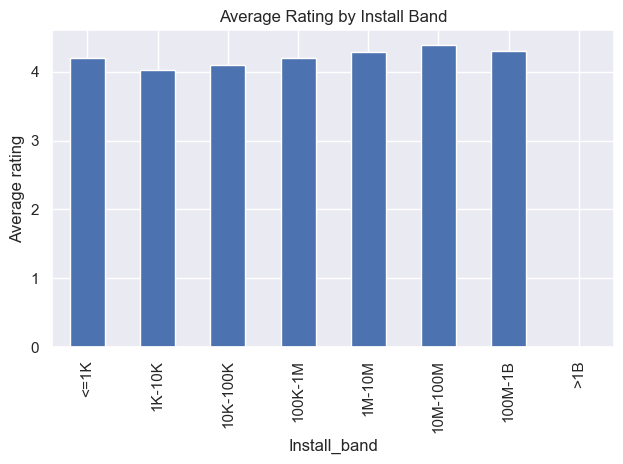

In [144]:
bins = [-1, 1_000, 10_000, 100_000, 1_000_000, 10_000_000, 100_000_000, 1_000_000_000, np.inf]
labels = ["<=1K", "1K-10K", "10K-100K", "100K-1M", "1M-10M", "10M-100M", "100M-1B", ">1B"]

apps_clean["Install_band"] = pd.cut(
    apps_clean["Installs_num"], bins=bins, labels=labels
)
rating_by_install_band = apps_clean.groupby(
    "Install_band", observed=False
)["Rating"].agg(["mean", "median", "count"])
display(rating_by_install_band)

rating_by_install_band["mean"].plot(kind="bar")
plt.title("Average Rating by Install Band")
plt.ylabel("Average rating")
plt.tight_layout()
plt.show()

### Advanced Q4 — Sentiment analysis on app reviews

In [145]:
display(reviews.head())
display(reviews["Sentiment"].value_counts(dropna=False).to_frame("Review count"))

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


,Review count
Sentiment,
NaN,26863
Positive,23998
Negative,8271
Neutral,5163


In [146]:
review_text_col = "Translated_Review"
reviews_with_text = reviews.dropna(subset=[review_text_col]).copy()
reviews_with_text[review_text_col] = reviews_with_text[review_text_col].astype(str).str.strip()
reviews_with_text = reviews_with_text[reviews_with_text[review_text_col] != ""]

display(reviews_with_text.groupby("Sentiment").size().to_frame("Reviews with text"))

,Reviews with text
Sentiment,
Negative,8271
Neutral,5158
Positive,23998


#### Look at examples of positive and negative feedback

In [147]:
for sentiment in ["Positive", "Negative", "Neutral"]:
    print("\\n---", sentiment, "examples ---")
    sample = reviews_with_text.loc[
        reviews_with_text["Sentiment"] == sentiment, review_text_col
    ].head(5)
    for text in sample:
        print("-", text[:300])

\n--- Positive examples ---
- I like eat delicious food. That's I'm cooking food myself, case "10 Best Foods" helps lot, also "Best Before (Shelf Life)"
- This help eating healthy exercise regular basis
- Works great especially going grocery store
- Best idea us
- Best way
\n--- Negative examples ---
- No recipe book Unable recipe book.
- Waste time It needs internet time n ask calls information
- Faltu plz waste ur time
- Crap Doesn't work
- Boring. I thought actually just texts that's it. Too poor old texts....
\n--- Neutral examples ---
- Looking forward app,
- It helpful site ! It help foods get !
- God health
- I found lot wealth form health...
- On test....


#### Compare sentiment polarity, if available

In [148]:
if "Sentiment_Polarity" in reviews.columns:
    reviews["Sentiment_Polarity"] = pd.to_numeric(reviews["Sentiment_Polarity"], errors="coerce")
    display(reviews.groupby("Sentiment")["Sentiment_Polarity"].agg(["mean", "median", "count"]))

,mean,median,count
Sentiment,,,
Negative,-0.256173,-0.183333,8271
Neutral,0.000000,0.000000,5163
Positive,0.372402,0.330000,23998


### Advanced Q5 — What is the relationship between genre and ratings?

In [149]:
genre_ratings = (
    apps_clean.groupby("Genres")
    .agg(mean_rating=("Rating", "mean"),
         median_rating=("Rating", "median"),
         app_count=("Rating", "count"))
)
genre_ratings = genre_ratings[genre_ratings["app_count"] >= 20].sort_values("mean_rating", ascending=False)
display(genre_ratings.head(10))
display(genre_ratings.tail(10))

,mean_rating,median_rating,app_count
Genres,,,
Events,4.435556,4.5,45
Word,4.396296,4.4,27
Puzzle,4.386325,4.4,117
Art & Design,4.358929,4.4,56
Education;Education,4.350000,4.4,44
Books & Reference,4.347458,4.5,177
Parenting,4.340000,4.5,40
Personalization,4.333871,4.4,310
Arcade,4.301951,4.4,205


,mean_rating,median_rating,app_count
Genres,,,
Lifestyle,4.096382,4.20,304
Travel & Local,4.094118,4.25,204
Entertainment,4.089558,4.20,498
Card,4.086667,4.20,45
Video Players & Editors,4.063924,4.20,158
Maps & Navigation,4.051613,4.20,124
Tools,4.046794,4.20,733
Trivia,4.039286,4.25,28
Dating,3.971698,4.10,159


## 8. Save cleaned data and results

In [151]:
apps_clean.to_csv("googleplaystore_cleaned.csv", index=False)
print("Saved cleaned app data to googleplaystore_cleaned.csv")

Saved cleaned app data to googleplaystore_cleaned.csv
